### SOFE4110U Group 16
Logan Yee [removed]: Part 1 & 2 \
Titobiloluwa Odufuye [removed]: Part 3 \
João Pedro Minari [removed]: Part 4


In [1]:
import torch
import numpy as np
from torch import nn
import matplotlib.pyplot as plt

# Part 1: Get Familiar with PyTorch

**Small Practice Task**

The function parameters are: nn.Linear(in_features, out_features).

The first 1 is the number of input features per sample, it must match the last dimension of the tensor (x), which has the shape (3, 1). 3 samples with 1 feature each.

The second 1 is the number of output features per sample.

Each prediction $= w * x + b$

Where w and b are random and untrained.

In [2]:
x = torch.tensor([[1.0], [2.0], [3.0]], dtype=torch.float32)

layer1 = nn.Linear(1, 1)

# only looking at inputs, not training
with torch.no_grad():
    predictions = layer1(x)

print(predictions)
print("weight:", layer1.weight)  # shape (1, 1)
print("bias:  ", layer1.bias)   # shape (1,)

tensor([[0.1209],
        [0.8331],
        [1.5452]])
weight: Parameter containing:
tensor([[0.7121]], requires_grad=True)
bias:   Parameter containing:
tensor([-0.5912], requires_grad=True)


# Part 2: Prepare the data

In [3]:
# Dataset A
rng_A = np.random.default_rng(4110)
x_A = rng_A.uniform(-2, 2, size=(300, 1))
y_A_clean = np.sin(2 * x_A) + 0.3 * x_A
y_A = y_A_clean + rng_A.normal(loc=0, scale=0.10, size=(300, 1))
idx_A = rng_A.permutation(300)

# Dataset B
rng_B = np.random.default_rng(4111)
x_B = rng_B.uniform(-2, 2, size=(900, 2))
x1, x2 = x_B[:, 0], x_B[:, 1]   #column 0 = x1, column 1 = x2
y_B_clean = np.column_stack([np.sin(2*x1) + 0.5*x2, 
                             np.cos(2*x2) + 0.5*x1])
y_B = y_B_clean + rng_B.normal(loc=0, scale=0.10, size=(900, 2))
idx_B = rng_B.permutation(900)

# Split and convert to float32 tensors
def to_tensor(arr):     # Helper function to turn numpy array into a float32 tensor
    return torch.tensor(arr, dtype=torch.float32)

# Dataset A: first 180 train, next 60 validate, last 60 test
train_A, val_A, test_A = idx_A[:180], idx_A[180:240], idx_A[240:300]
X_A_train, y_A_train = to_tensor(x_A[train_A]), to_tensor(y_A[train_A])     # Same indices for inputs and targets so each x keeps its matching y
X_A_val, y_A_val = to_tensor(x_A[val_A]), to_tensor(y_A[val_A])
X_A_test,  y_A_test  = to_tensor(x_A[test_A]),  to_tensor(y_A[test_A])

# Dataset B: first 540 train, next 180 val, last 180 test
train_B, val_B, test_B = idx_B[:540], idx_B[540:720], idx_B[720:]
X_B_train, y_B_train = to_tensor(x_B[train_B]), to_tensor(y_B[train_B])
X_B_val,   y_B_val   = to_tensor(x_B[val_B]),   to_tensor(y_B[val_B])
X_B_test,  y_B_test  = to_tensor(x_B[test_B]),  to_tensor(y_B[test_B])

# Check the sizes: one row per example, A has 1 column, B has 2
print("A train:", X_A_train.shape, y_A_train.shape, X_A_train.dtype)
print("A val:  ", X_A_val.shape,   y_A_val.shape)
print("A test: ", X_A_test.shape,  y_A_test.shape)
print("B train:", X_B_train.shape, y_B_train.shape, X_B_train.dtype)
print("B val:  ", X_B_val.shape,   y_B_val.shape)
print("B test: ", X_B_test.shape,  y_B_test.shape)

A train: torch.Size([180, 1]) torch.Size([180, 1]) torch.float32
A val:   torch.Size([60, 1]) torch.Size([60, 1])
A test:  torch.Size([60, 1]) torch.Size([60, 1])
B train: torch.Size([540, 2]) torch.Size([540, 2]) torch.float32
B val:   torch.Size([180, 2]) torch.Size([180, 2])
B test:  torch.Size([180, 2]) torch.Size([180, 2])


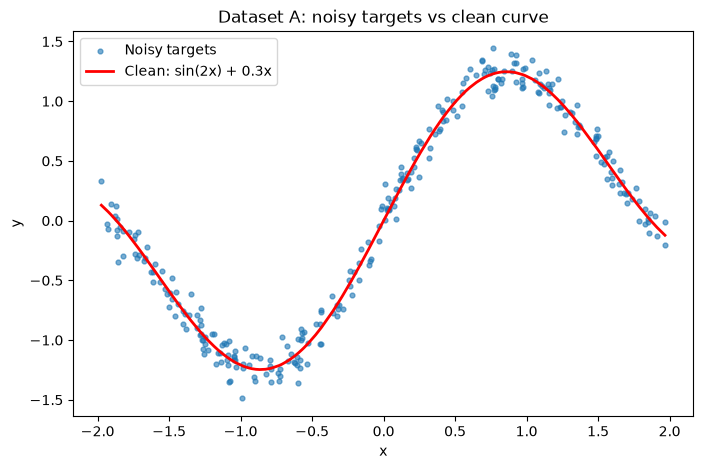

In [4]:
# Plot Dataset A

# Sort inputs so the 'clean' curve draws smoothly
x_sorted = np.sort(x_A, axis=0)
y_sorted_clean = np.sin(2 * x_sorted) + 0.3 * x_sorted

plt.figure(figsize=(8, 5))
plt.scatter(x_A, y_A, s=12, alpha=0.6, label="Noisy targets")
plt.plot(x_sorted, y_sorted_clean, color="red", linewidth=2, label="Clean: sin(2x) + 0.3x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Dataset A: noisy targets vs clean curve")
plt.legend()
plt.show()

# Part 3: Build and train  your first network

In [5]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")


# Convert the data to float 32 tensors with shape (N, 1) for inputs and (N, 1) for targets
X_A_train = torch.as_tensor(X_A_train, dtype=torch.float32).reshape(-1, 1)
y_A_train = torch.as_tensor(y_A_train, dtype=torch.float32).reshape(-1, 1)
X_A_val = torch.as_tensor(X_A_val, dtype=torch.float32).reshape(-1, 1)
y_A_val = torch.as_tensor(y_A_val, dtype=torch.float32).reshape(-1, 1)

# Set the seed BEFORE  creating the model.
torch.manual_seed(4110)

model_A = nn.Sequential(
    nn.Linear(1,3),
    nn.ReLU(),
    nn.Linear(3,1)
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model_A.parameters(), lr=0.01)

train_mse_history = []
val_mse_history = []

for epoch in range(2000):
    model_A.train()

    # 1. Remove gradients left over from the previous update.
    optimizer.zero_grad()

    # 2. Predict outputs for the entire training set.
    predictions = model_A(X_A_train)

    # 3. Measure the difference between predictions and targets.
    loss = loss_fn(predictions, y_A_train)

    # 4. Find how each parameter affects the loss.
    loss.backward()

    # 5. Adjust the weights and biases using their gradients.
    optimizer.step()

    # Measure both errors using the updated parameters.
    model_A.eval()
    with torch.no_grad():
        train_mse = loss_fn(model_A(X_A_train), y_A_train).item()
        val_mse = loss_fn(model_A(X_A_val), y_A_val).item()

    train_mse_history.append(train_mse)
    val_mse_history.append(val_mse)

    # Display progress every 500 epochs.
    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Training MSE = {train_mse:.6f}, "
            f"Validation MSE = {val_mse:.6f}"
        )


Using cuda device
Epoch 500: Training MSE = 0.231695, Validation MSE = 0.252529
Epoch 1000: Training MSE = 0.149005, Validation MSE = 0.152346
Epoch 1500: Training MSE = 0.104328, Validation MSE = 0.097318
Epoch 2000: Training MSE = 0.089885, Validation MSE = 0.078076


In [6]:
def train_model(hidden_neurons):
    torch.manual_seed(0)

    model = nn.Sequential(
        nn.Linear(1, hidden_neurons),
        nn.ReLU(),
        nn.Linear(hidden_neurons, 1)
    )

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

    train_history = []
    val_history = []

    for epoch in range(2000):
        model.train()

        # Clear gradients from the previous update.
        optimizer.zero_grad()

        # Predict the training outputs and measure their error.
        predictions = model(X_A_train)
        loss = loss_fn(predictions, y_A_train)

        # Calculate gradients, then update weights and biases.
        loss.backward()
        optimizer.step()

        # Record errors after the update without tracking gradients.
        model.eval()
        with torch.no_grad():
            train_mse = loss_fn(model(X_A_train), y_A_train).item()
            val_mse = loss_fn(model(X_A_val), y_A_val).item()

        train_history.append(train_mse)
        val_history.append(val_mse)

    return {
        "model": model,
        "train_history": train_history,
        "val_history": val_history
    }

results = {}
for neurons in (3, 10):
    results[neurons] = train_model(neurons)

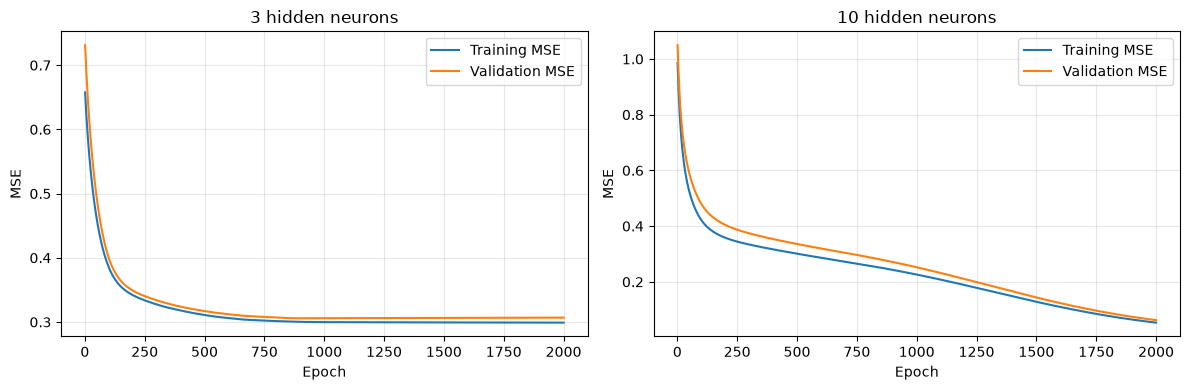

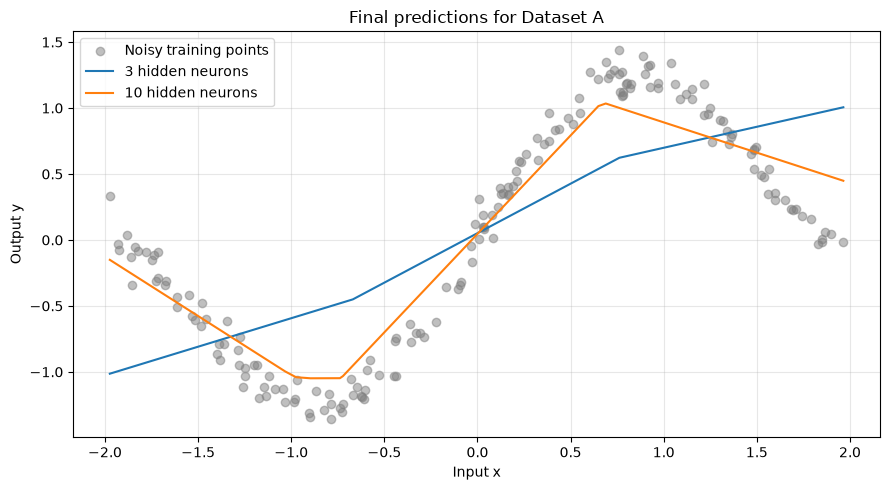

In [7]:
# Training and validation loss against epoch.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, neurons in zip(axes, (3, 10)):
    run = results[neurons]
    epochs = range(1, len(run["train_history"]) + 1)

    ax.plot(epochs, run["train_history"], label="Training MSE")
    ax.plot(epochs, run["val_history"], label="Validation MSE")
    ax.set_title(f"{neurons} hidden neurons")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Sort inputs so the prediction lines connect in the correct order.
X_sorted = torch.sort(X_A_train, dim=0).values

plt.figure(figsize=(9, 5))
plt.scatter(
    X_A_train.numpy().ravel(),
    y_A_train.numpy().ravel(),
    label="Noisy training points",
    color="gray",
    alpha=0.5
)

with torch.no_grad():
    for neurons in (3, 10):
        predictions = results[neurons]["model"](X_sorted)
        plt.plot(
            X_sorted.numpy().ravel(),
            predictions.numpy().ravel(),
            label=f"{neurons} hidden neurons"
        )

plt.xlabel("Input x")
plt.ylabel("Output y")
plt.title("Final predictions for Dataset A")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
from IPython.display import Markdown, display

table = (
    "| Hidden neurons | Total parameters | Final training MSE | Final validation MSE |\n"
    "|---:|---:|---:|---:|\n"
)

for neurons, run in results.items():
    count = sum(p.numel() for p in run["model"].parameters())
    train_mse = run["train_history"][-1]
    val_mse = run["val_history"][-1]

    table += (
        f"| {neurons} | {count} | "
        f"{train_mse:.6f} | {val_mse:.6f} |\n"
    )

display(Markdown(table))

# Select the lowest final validation MSE; prefer fewer neurons in a tie.
selected = min(
    results,
    key=lambda n: (results[n]["val_history"][-1], n)
)

chosen_model = results[selected]["model"]
chosen_model.eval()

with torch.no_grad():
    test_mse = nn.MSELoss()(
        chosen_model(X_A_test), y_A_test
    ).item()

selected_val_mse = results[selected]["val_history"][-1]
effect = (
    "improved"
    if results[10]["val_history"][-1] < results[3]["val_history"][-1]
    else "did not improve"
)

print(
    f"I selected the model with {selected} hidden neurons because "
    f"it achieved the lowest final validation MSE "
    f"({selected_val_mse:.6f}). "
    "I used validation performance to make this choice before "
    "evaluating the test set. "
    f"The selected model's test MSE was {test_mse:.6f}. "
    f"In this run, increasing the hidden neurons from 3 to 10 "
    f"{effect} validation MSE."
)

| Hidden neurons | Total parameters | Final training MSE | Final validation MSE |
|---:|---:|---:|---:|
| 3 | 10 | 0.299035 | 0.306810 |
| 10 | 31 | 0.053535 | 0.062400 |


I selected the model with 10 hidden neurons because it achieved the lowest final validation MSE (0.062400). I used validation performance to make this choice before evaluating the test set. The selected model's test MSE was 0.066894. In this run, increasing the hidden neurons from 3 to 10 improved validation MSE.


# Part 4: Adapt the network to two inputs and two outputs

Dataset B has two input features (`x1`, `x2`) and two target values (`y1`, `y2`). I use one shared hidden layer with 10 neurons: `Linear(2, 10)`, ReLU, and `Linear(10, 2)`. The first and last layer sizes change because the model must accept two features and produce two outputs, but the training-loop steps remain the same because backpropagation and MSE work with tensors containing multiple output columns.

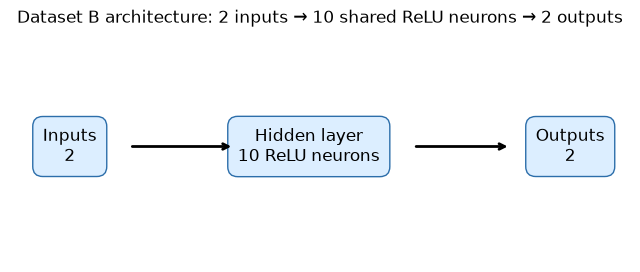

Parameter breakdown: {'input_to_hidden_weights': 20, 'hidden_biases': 10, 'hidden_to_output_weights': 20, 'output_biases': 2}
Total weights and biases: 52
Final training MSE: 0.229389
Final validation MSE: 0.226020


In [9]:
# Architecture diagram: both outputs share the same hidden layer.
fig, ax = plt.subplots(figsize=(8, 3))
layers = [(0.08, 'Inputs\n2'), (0.40, 'Hidden layer\n10 ReLU neurons'), (0.75, 'Outputs\n2')]
for x_pos, label in layers:
    ax.text(x_pos, 0.5, label, ha='center', va='center', fontsize=12,
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#dceeff', edgecolor='#2c6eaa'))
ax.annotate('', xy=(0.30, 0.5), xytext=(0.16, 0.5), arrowprops=dict(arrowstyle='->', lw=2))
ax.annotate('', xy=(0.67, 0.5), xytext=(0.54, 0.5), arrowprops=dict(arrowstyle='->', lw=2))
ax.set_xlim(0, 0.83); ax.set_ylim(0, 1); ax.axis('off')
plt.title('Dataset B architecture: 2 inputs → 10 shared ReLU neurons → 2 outputs')
plt.show()

def train_model_B(hidden_neurons=10, epochs=2000):
    torch.manual_seed(4110)

    model = nn.Sequential(
        nn.Linear(2, hidden_neurons),
        nn.ReLU(),
        nn.Linear(hidden_neurons, 2)
    )

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
    train_history, val_history = [], []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        predictions = model(X_B_train)
        loss = loss_fn(predictions, y_B_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            train_mse = loss_fn(model(X_B_train), y_B_train).item()
            val_mse = loss_fn(model(X_B_val), y_B_val).item()
        train_history.append(train_mse)
        val_history.append(val_mse)

    return {"model": model, "train_history": train_history, "val_history": val_history}

run_B = train_model_B()
model_B = run_B['model']
parameter_breakdown = {
    'input_to_hidden_weights': 2 * 10,
    'hidden_biases': 10,
    'hidden_to_output_weights': 10 * 2,
    'output_biases': 2,
}
total_parameters_B = sum(parameter_breakdown.values())
print('Parameter breakdown:', parameter_breakdown)
print(f'Total weights and biases: {total_parameters_B}')
print(f'Final training MSE: {run_B["train_history"][-1]:.6f}')
print(f'Final validation MSE: {run_B["val_history"][-1]:.6f}')

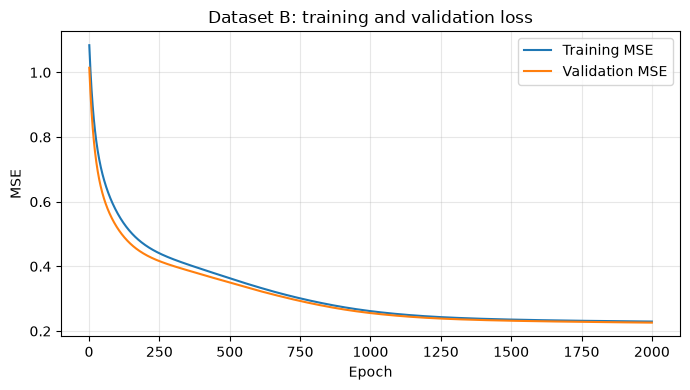

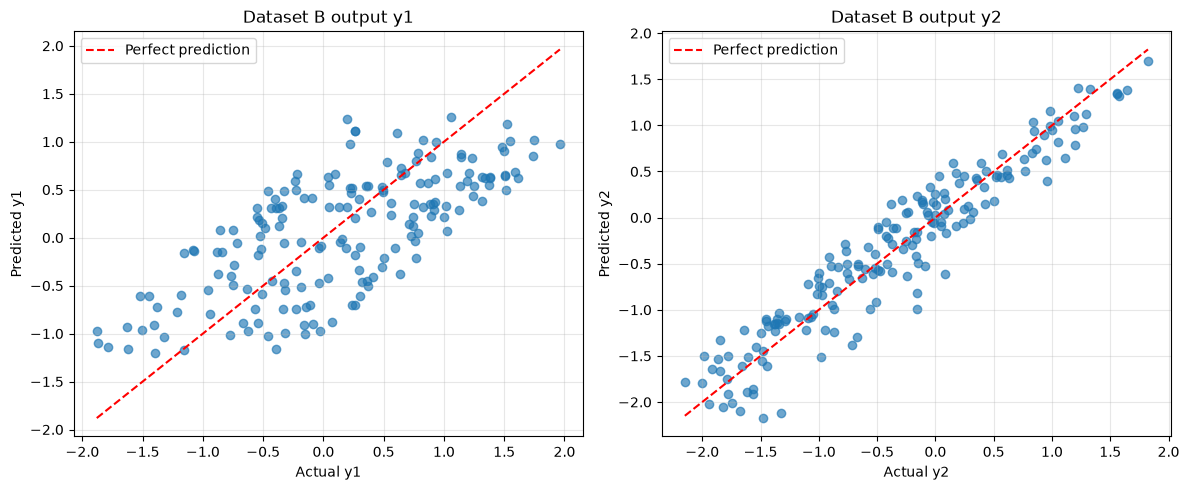

Test MSE across both outputs: 0.225262
Test MSE for y1: 0.370671
Test MSE for y2: 0.079854


In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
epochs = range(1, len(run_B['train_history']) + 1)
ax.plot(epochs, run_B['train_history'], label='Training MSE')
ax.plot(epochs, run_B['val_history'], label='Validation MSE')
ax.set_title('Dataset B: training and validation loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

chosen_model_B = model_B
chosen_model_B.eval()
with torch.no_grad():
    test_predictions_B = chosen_model_B(X_B_test)
    test_mse_B = nn.MSELoss()(test_predictions_B, y_B_test).item()
    test_mse_y1 = nn.MSELoss()(test_predictions_B[:, 0], y_B_test[:, 0]).item()
    test_mse_y2 = nn.MSELoss()(test_predictions_B[:, 1], y_B_test[:, 1]).item()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for output_index, ax in enumerate(axes):
    ax.scatter(y_B_test[:, output_index].numpy(), test_predictions_B[:, output_index].numpy(), alpha=0.65)
    limits = [y_B_test[:, output_index].min().item(), y_B_test[:, output_index].max().item()]
    ax.plot(limits, limits, 'r--', label='Perfect prediction')
    ax.set_xlabel(f'Actual y{output_index + 1}')
    ax.set_ylabel(f'Predicted y{output_index + 1}')
    ax.set_title(f'Dataset B output y{output_index + 1}')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    f'Test MSE across both outputs: {test_mse_B:.6f}\n'
    f'Test MSE for y1: {test_mse_y1:.6f}\n'
    f'Test MSE for y2: {test_mse_y2:.6f}'
)